# Landmark Recognition Using the SIFT Algorithm

## Setup

In [19]:
import os
import time
import pickle
import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.14.0


## Configuration

In [20]:
LANDMARKS = {
    "Eiffel Tower": "Category:Eiffel Tower",
    "Taj Mahal": "Category:Taj Mahal",
    "Great Wall of China": "Category:Great Wall of China",
    "Statue of Liberty": "Category:Statue of Liberty",
    "Colosseum": "Category:Colosseum",
}
KEYWORDS = {
    "Eiffel Tower": ("eiffel",),
    "Taj Mahal": ("taj",),
    "Great Wall of China": ("great wall", "wall"),
    "Statue of Liberty": ("liberty",),
    "Colosseum": ("colosseum", "coliseum", "colosseo"),
    "Great Pyramid of Giza": ("pyramid", "giza"),
}
EXCLUDED_WORDS = ("map", "diagram", "logo", "flag", "drawing", "plan", "poster", "stamp",
                  "postcard", "model", "replica", "lego", "painting", "sketch", "icon",
                  "interior", "inside", "plaque", "sign", "museum", "exhibit", "display", "bust",
                  "torch", "engraving", "banknote", "coin", "panorama", "detail", "portrait",
                  "selfie", "person", "people", "crowd", "ticket", "souvenir", "toy")
MIN_ASPECT, MAX_ASPECT = 0.6, 1.8

UNKNOWN_NAME = "Great Pyramid of Giza"
UNKNOWN_CATEGORY = "Category:Great Pyramid of Giza"

DB_DIR = "landmark_db"
UNKNOWN_DIR = "unknown_query"
IMAGES_PER_LANDMARK = 10
FORCE_REDOWNLOAD = True
HELD_OUT = 1
MAX_SIDE = 800

COMMONS_API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "CV-SIFT-Landmark-Lab/1.0 (student assignment)"}

RATIO = 0.75
MIN_GOOD = 15
MIN_INLIERS = 12
MARGIN = 1.5
RANSAC_THRESH = 5.0

## Task 1: Landmark Image Database

In [21]:
def query_commons(extra_params):
    params = {
        "action": "query",
        "format": "json",
        "prop": "imageinfo",
        "iiprop": "url|mime|size",
        "iiurlwidth": MAX_SIDE,
    }
    params.update(extra_params)
    response = requests.get(COMMONS_API, params=params, headers=HEADERS, timeout=30)
    response.raise_for_status()
    pages = response.json().get("query", {}).get("pages", {})
    return sorted(pages.values(), key=lambda p: p.get("index", 0))


def usable(page, keywords=None):
    title = page.get("title", "").lower()
    info = page.get("imageinfo", [{}])[0]
    if info.get("mime") != "image/jpeg" or info.get("width", 0) < MAX_SIDE or not info.get("thumburl"):
        return False
    if any(w in title for w in EXCLUDED_WORDS):
        return False
    aspect = info["width"] / max(info.get("height", 1), 1)
    if not MIN_ASPECT <= aspect <= MAX_ASPECT:
        return False
    if keywords and not any(k in title for k in keywords):
        return False
    return True


def fetch_image_urls(name, category, limit):
    keywords = KEYWORDS[name]
    urls = []
    pages = query_commons({"generator": "categorymembers", "gcmtitle": category,
                           "gcmtype": "file", "gcmlimit": 50})
    urls += [p["imageinfo"][0]["thumburl"] for p in pages if usable(p)]
    for offset in (0, 50, 100):
        if len(urls) >= limit * 3:
            break
        pages = query_commons({"generator": "search", "gsrsearch": f"{name} filetype:bitmap",
                               "gsrnamespace": 6, "gsrlimit": 50, "gsroffset": offset})
        urls += [p["imageinfo"][0]["thumburl"] for p in pages if usable(p, keywords)]
    return list(dict.fromkeys(urls))


def download_images(name, category, count, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    existing = [f for f in os.listdir(out_dir) if f.endswith(".jpg")]
    if len(existing) >= count and not FORCE_REDOWNLOAD:
        return len(existing)
    for f in existing:
        os.remove(os.path.join(out_dir, f))
    prefix = name.replace(" ", "_").lower()
    saved = 0
    for url in fetch_image_urls(name, category, count):
        if saved >= count:
            break
        for attempt in range(3):
            r = requests.get(url, headers=HEADERS, timeout=60)
            if r.status_code == 200:
                break
            time.sleep(2 * (attempt + 1))
        else:
            continue
        img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            continue
        saved += 1
        cv2.imwrite(os.path.join(out_dir, f"{prefix}_{saved:02d}.jpg"), img)
        time.sleep(0.5)
    return saved


for name, category in LANDMARKS.items():
    n = download_images(name, category, IMAGES_PER_LANDMARK, os.path.join(DB_DIR, name))
    print(f"{name}: {n} images")

n = download_images(UNKNOWN_NAME, UNKNOWN_CATEGORY, 1, UNKNOWN_DIR)
print(f"{UNKNOWN_NAME} (not in database): {n} image")

Eiffel Tower: 10 images
Taj Mahal: 10 images
Great Wall of China: 10 images
Statue of Liberty: 10 images
Colosseum: 10 images
Great Pyramid of Giza (not in database): 1 image


In [22]:
def load_image(path):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    scale = MAX_SIDE / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return img


image_paths = {}
for name in LANDMARKS:
    folder = os.path.join(DB_DIR, name)
    image_paths[name] = sorted(os.path.join(folder, f) for f in os.listdir(folder) if f.endswith(".jpg"))
    assert len(image_paths[name]) > HELD_OUT + 1, f"Not enough images for {name}"

reference_paths = {n: p[:-HELD_OUT] for n, p in image_paths.items()}
base_images = {n: load_image(reference_paths[n][0]) for n in LANDMARKS}
viewpoint_images = {n: load_image(p[-1]) for n, p in image_paths.items()}
unknown_image = load_image(os.path.join(UNKNOWN_DIR, sorted(os.listdir(UNKNOWN_DIR))[0]))

summary = pd.DataFrame({
    "Landmark": list(LANDMARKS),
    "Reference images": [len(reference_paths[n]) for n in LANDMARKS],
    "Held-out viewpoint images": [HELD_OUT] * len(LANDMARKS),
})
summary

,Landmark,Reference images,Held-out viewpoint images
0,Eiffel Tower,9,1
1,Taj Mahal,9,1
2,Great Wall of China,9,1
3,Statue of Liberty,9,1
4,Colosseum,9,1


## Image Transformations

In [23]:
def rotate_image(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    new_w, new_h = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += new_w / 2 - w / 2
    M[1, 2] += new_h / 2 - h / 2
    return cv2.warpAffine(img, M, (new_w, new_h))


def resize_image(img, factor):
    return cv2.resize(img, None, fx=factor, fy=factor, interpolation=cv2.INTER_AREA)


def darken_image(img, factor):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)

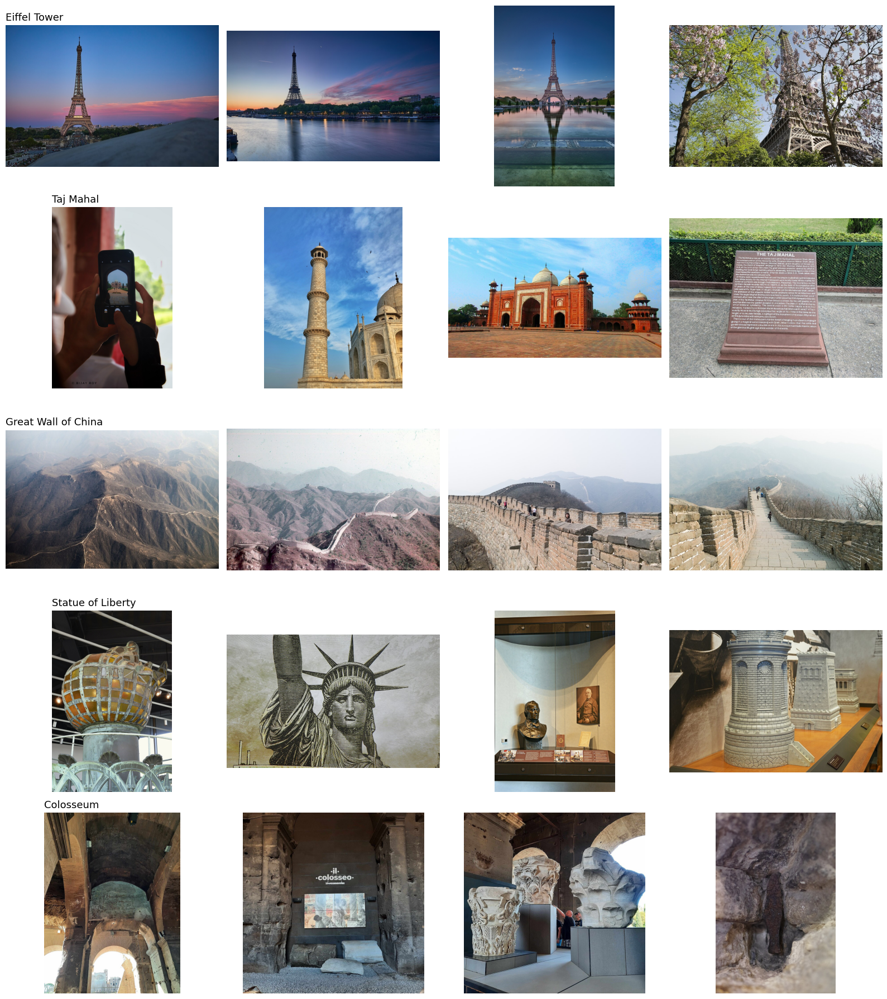

In [24]:
fig, axes = plt.subplots(len(LANDMARKS), 4, figsize=(16, 3.6 * len(LANDMARKS)))
for r, name in enumerate(LANDMARKS):
    for c in range(4):
        img = load_image(reference_paths[name][c])
        axes[r, c].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(name, loc="left", fontsize=13)
plt.tight_layout()
plt.savefig("fig_01_database_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 2: SIFT Feature Extraction

In [25]:
sift = cv2.SIFT_create(nfeatures=3000, contrastThreshold=0.02)


def extract(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    return gray, keypoints, descriptors


database = {}
for name, paths in reference_paths.items():
    database[name] = []
    for p in paths:
        img = load_image(p)
        gray, kp, des = extract(img)
        database[name].append({"path": p, "img": img, "gray": gray, "kp": kp, "des": des})

stats = pd.DataFrame({
    "Landmark": list(database),
    "Reference images": [len(v) for v in database.values()],
    "Total keypoints": [sum(len(r["kp"]) for r in v) for v in database.values()],
    "Avg keypoints per image": [round(np.mean([len(r["kp"]) for r in v])) for v in database.values()],
})
stats

,Landmark,Reference images,Total keypoints,Avg keypoints per image
0,Eiffel Tower,9,18267,2030
1,Taj Mahal,9,22284,2476
2,Great Wall of China,9,22188,2465
3,Statue of Liberty,9,21880,2431
4,Colosseum,9,25673,2853


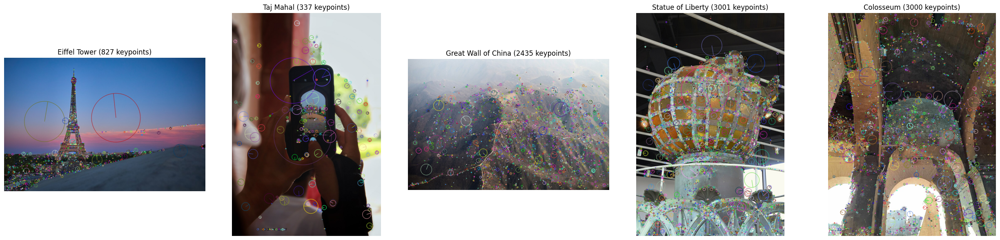

In [26]:
fig, axes = plt.subplots(1, len(database), figsize=(5 * len(database), 6))
for ax, (name, refs) in zip(axes, database.items()):
    ref = refs[0]
    vis = cv2.drawKeypoints(ref["img"], ref["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name} ({len(ref['kp'])} keypoints)")
    ax.axis("off")
plt.tight_layout()
plt.savefig("fig_02_reference_keypoints.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
def kp_to_tuple(kp):
    return (kp.pt, kp.size, kp.angle, kp.response, kp.octave, kp.class_id)


stored = {
    name: [{"path": r["path"], "keypoints": [kp_to_tuple(k) for k in r["kp"]], "descriptors": r["des"]} for r in refs]
    for name, refs in database.items()
}
with open("sift_descriptors.pkl", "wb") as f:
    pickle.dump(stored, f)

print("Saved sift_descriptors.pkl:", os.path.getsize("sift_descriptors.pkl") // 1024, "KB")

Saved sift_descriptors.pkl: 61614 KB


## Task 3: Query Image Processing

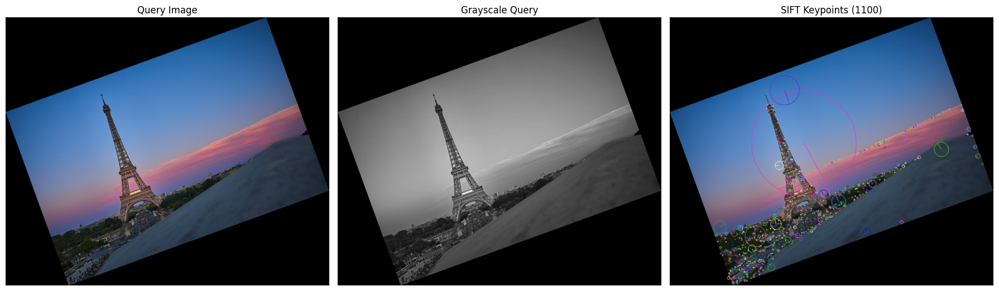

Descriptor shape: (1100, 128)


In [28]:
demo_name = "Eiffel Tower"
demo_img = rotate_image(base_images[demo_name], 20)
demo_gray, demo_kp, demo_des = extract(demo_img)

demo_vis = cv2.drawKeypoints(demo_img, demo_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(cv2.cvtColor(demo_img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Query Image")
axes[1].imshow(demo_gray, cmap="gray")
axes[1].set_title("Grayscale Query")
axes[2].imshow(cv2.cvtColor(demo_vis, cv2.COLOR_BGR2RGB))
axes[2].set_title(f"SIFT Keypoints ({len(demo_kp)})")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("fig_03_query_keypoints.png", dpi=150, bbox_inches="tight")
plt.show()

print("Descriptor shape:", demo_des.shape)

## Task 4: Feature Matching and Landmark Recognition

In [29]:
matcher = cv2.BFMatcher(cv2.NORM_L2)


def for_drawing(matches):
    return [cv2.DMatch(m.trainIdx, m.queryIdx, m.distance) for m in matches]


def ratio_test_matches(des_query, des_ref):
    if des_query is None or des_ref is None or len(des_query) < 2 or len(des_ref) < 2:
        return []
    pairs = matcher.knnMatch(des_query, des_ref, k=2)
    return [p[0] for p in pairs if len(p) == 2 and p[0].distance < RATIO * p[1].distance]


def rank_landmarks(des_query):
    rows = []
    for name, refs in database.items():
        best_count, best_idx, best_matches, total = 0, None, [], 0
        for i, ref in enumerate(refs):
            good = ratio_test_matches(des_query, ref["des"])
            total += len(good)
            if len(good) > best_count:
                best_count, best_idx, best_matches = len(good), i, good
        rows.append({"landmark": name, "reliable_matches": best_count, "total_matches": total,
                     "best_ref": best_idx, "matches": best_matches})
    return sorted(rows, key=lambda r: r["reliable_matches"], reverse=True)


demo_ranking = rank_landmarks(demo_des)

ranking_table = pd.DataFrame([
    {"Rank": i + 1, "Landmark": r["landmark"], "Reliable matches (best image)": r["reliable_matches"],
     "Reliable matches (all images)": r["total_matches"]}
    for i, r in enumerate(demo_ranking)
])
ranking_table

,Rank,Landmark,Reliable matches (best image),Reliable matches (all images)
0,1,Eiffel Tower,566,678
1,2,Statue of Liberty,19,82
2,3,Colosseum,19,87
3,4,Great Wall of China,16,88
4,5,Taj Mahal,15,79


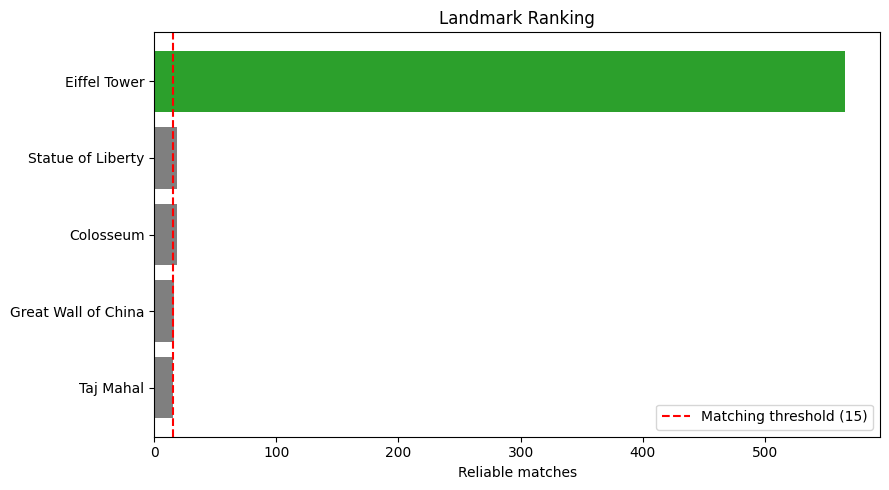

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
names = [r["landmark"] for r in demo_ranking]
counts = [r["reliable_matches"] for r in demo_ranking]
colors = ["tab:green"] + ["tab:gray"] * (len(names) - 1)
ax.barh(names[::-1], counts[::-1], color=colors[::-1])
ax.axvline(MIN_GOOD, color="red", linestyle="--", label=f"Matching threshold ({MIN_GOOD})")
ax.set_xlabel("Reliable matches")
ax.set_title("Landmark Ranking")
ax.legend()
plt.tight_layout()
plt.savefig("fig_04_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

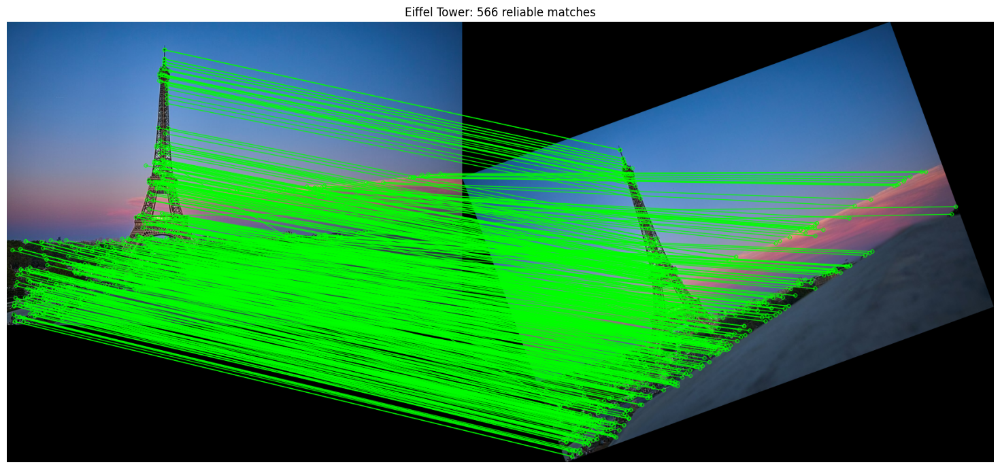

In [31]:
top = demo_ranking[0]
top_ref = database[top["landmark"]][top["best_ref"]]

match_vis = cv2.drawMatches(top_ref["img"], top_ref["kp"], demo_img, demo_kp, for_drawing(top["matches"]), None,
                            matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(18, 7))
plt.imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
plt.title(f"{top['landmark']}: {top['reliable_matches']} reliable matches")
plt.axis("off")
plt.tight_layout()
plt.savefig("fig_04_matches.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 5: Landmark Localization

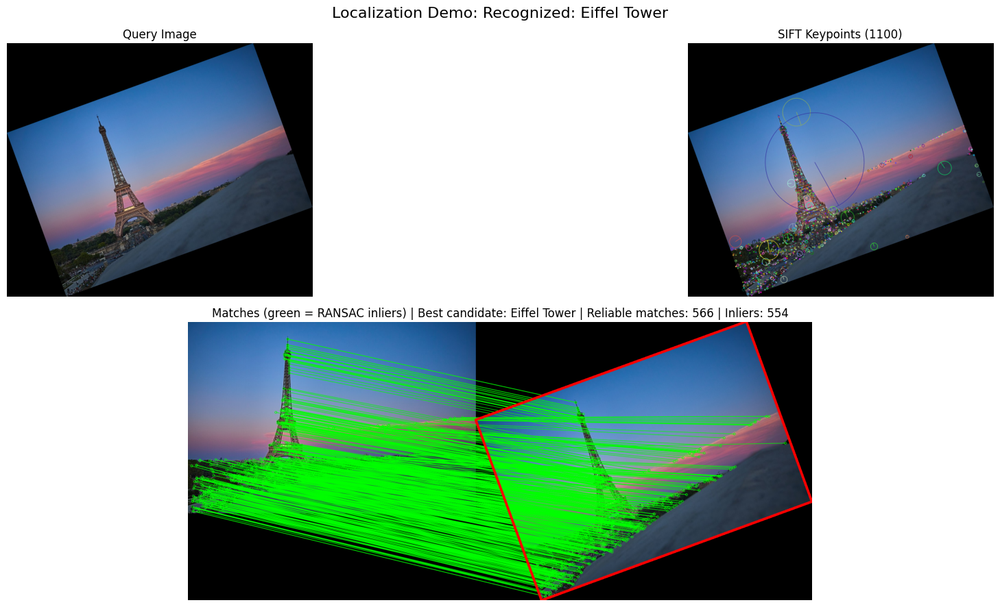

Predicted landmark : Eiffel Tower
Reliable matches   : 566
RANSAC inliers     : 554
Status             : Recognized: Eiffel Tower


In [32]:
def estimate_homography(kp_query, ref, matches):
    if len(matches) < 4:
        return None, 0, None
    src = np.float32([ref["kp"][m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    dst = np.float32([kp_query[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None:
        return None, 0, None
    h, w = ref["gray"].shape
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    polygon = cv2.perspectiveTransform(corners, H)
    return polygon, int(mask.sum()), mask


def polygon_is_valid(polygon, query_shape):
    pts = polygon.reshape(-1, 2).astype(np.float32)
    if not np.isfinite(pts).all():
        return False
    if not cv2.isContourConvex(np.int32(pts).reshape(-1, 1, 2)):
        return False
    area = cv2.contourArea(pts)
    qh, qw = query_shape[:2]
    return 0.02 * qh * qw < area < 4 * qh * qw


def recognize(img_bgr):
    start = time.perf_counter()
    gray, kp, des = extract(img_bgr)
    ranking = rank_landmarks(des)
    top, second = ranking[0], ranking[1]
    ref, polygon, inliers, mask = None, None, 0, None
    if top["best_ref"] is not None:
        ref = database[top["landmark"]][top["best_ref"]]
        polygon, inliers, mask = estimate_homography(kp, ref, top["matches"])
    geometry_ok = polygon is not None and inliers >= MIN_INLIERS and polygon_is_valid(polygon, img_bgr.shape)
    enough = top["reliable_matches"] >= MIN_GOOD
    distinct = top["reliable_matches"] >= MARGIN * max(second["reliable_matches"], 1)
    recognized = enough and distinct and geometry_ok
    if recognized:
        message = f"Recognized: {top['landmark']}"
    elif not enough:
        message = "Rejected: not enough reliable matches"
    elif not distinct:
        message = "Rejected: ambiguous between landmarks"
    else:
        message = "Rejected: geometric transformation unreliable"
    return {
        "image": img_bgr, "kp": kp, "ranking": ranking, "top": top, "ref": ref, "polygon": polygon,
        "inliers": inliers, "mask": mask, "geometry_ok": geometry_ok, "recognized": recognized,
        "message": message, "time": time.perf_counter() - start,
    }


def match_panel(res):
    if res["ref"] is None:
        return cv2.cvtColor(res["image"], cv2.COLOR_BGR2RGB)
    ref = res["ref"]
    mask = res["mask"].ravel().tolist() if res["mask"] is not None else None
    canvas = cv2.drawMatches(ref["img"], ref["kp"], res["image"], res["kp"], for_drawing(res["top"]["matches"]), None,
                             matchColor=(0, 255, 0), matchesMask=mask,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    if res["geometry_ok"]:
        shifted = res["polygon"].reshape(-1, 2) + np.array([ref["img"].shape[1], 0])
        cv2.polylines(canvas, [np.int32(shifted)], True, (0, 0, 255), 5)
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)


def show_result(res, title, save_name):
    fig = plt.figure(figsize=(20, 9))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
    ax1, ax2, ax3 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
    ax1.imshow(cv2.cvtColor(res["image"], cv2.COLOR_BGR2RGB))
    ax1.set_title("Query Image")
    vis = cv2.drawKeypoints(res["image"], res["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax2.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax2.set_title(f"SIFT Keypoints ({len(res['kp'])})")
    ax3.imshow(match_panel(res))
    ax3.set_title(f"Matches (green = RANSAC inliers) | Best candidate: {res['top']['landmark']} | "
                  f"Reliable matches: {res['top']['reliable_matches']} | Inliers: {res['inliers']}")
    for ax in (ax1, ax2, ax3):
        ax.axis("off")
    fig.suptitle(f"{title}: {res['message']}", fontsize=16)
    plt.tight_layout()
    plt.savefig(save_name, dpi=150, bbox_inches="tight")
    plt.show()


demo_result = recognize(demo_img)
show_result(demo_result, "Localization Demo", "fig_05_localization.png")

print("Predicted landmark :", demo_result["top"]["landmark"])
print("Reliable matches   :", demo_result["top"]["reliable_matches"])
print("RANSAC inliers     :", demo_result["inliers"])
print("Status             :", demo_result["message"])

## Task 6: Performance Evaluation

In [33]:
def build_tests(name):
    base = base_images[name]
    return [
        ("Original", name, base),
        ("Rotated (45 deg)", name, rotate_image(base, 45)),
        ("Resized (50%)", name, resize_image(base, 0.5)),
        ("Reduced brightness", name, darken_image(base, 0.4)),
        ("Different viewpoint", name, viewpoint_images[name]),
    ]

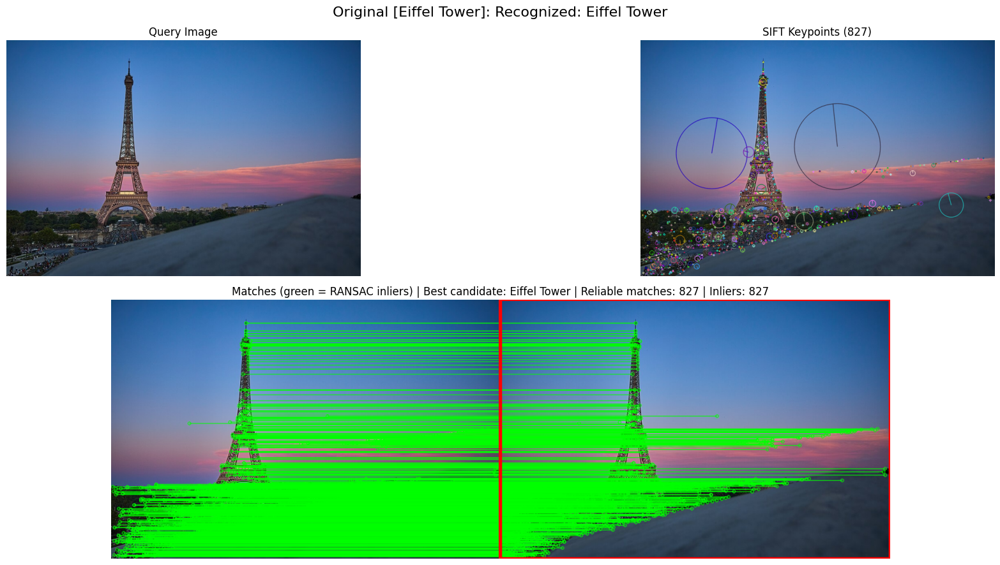

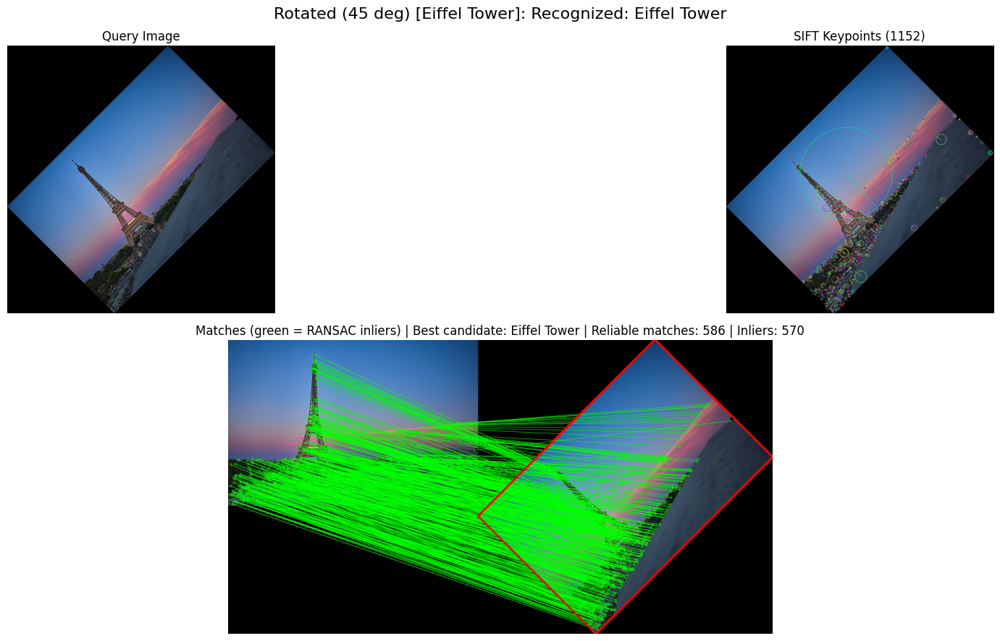

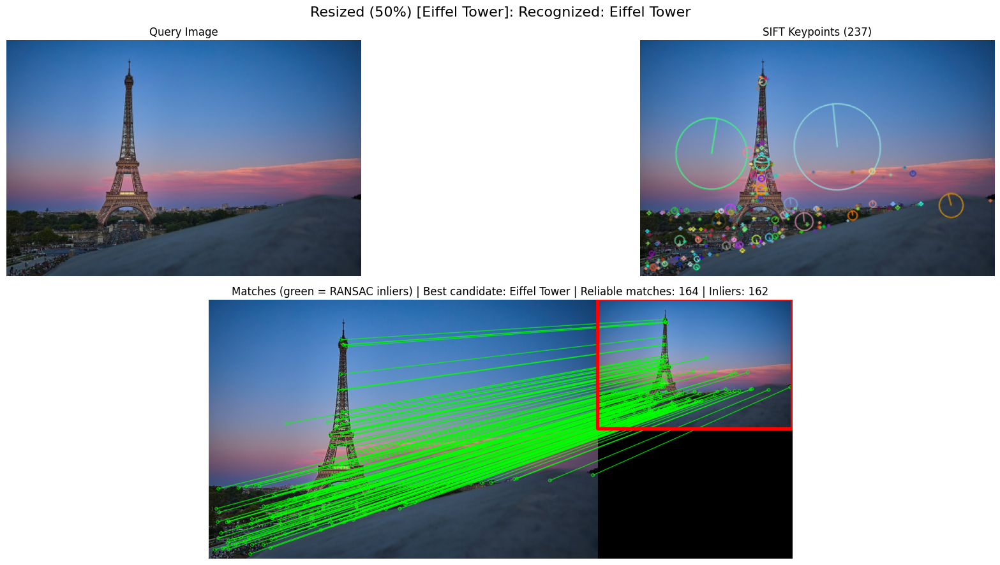

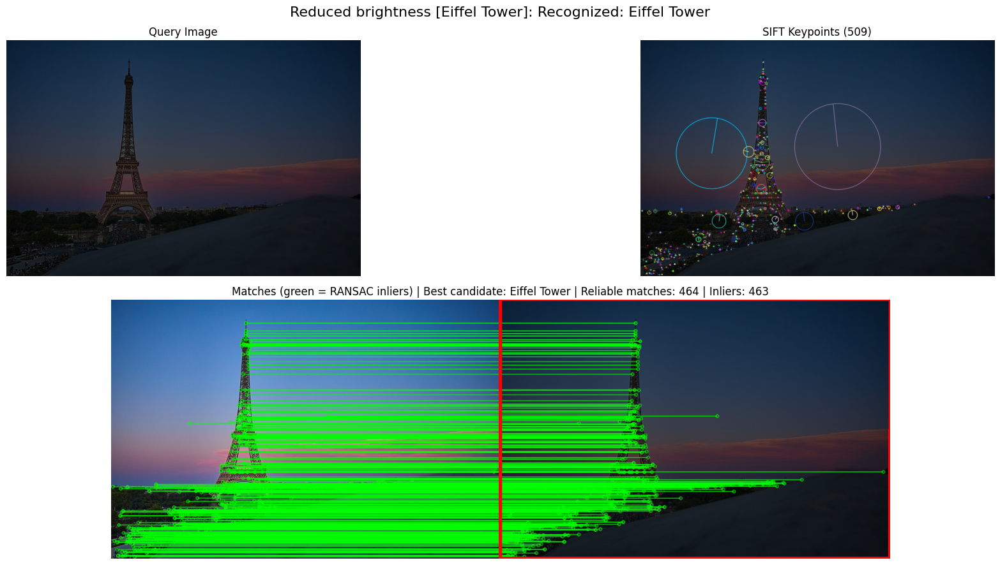

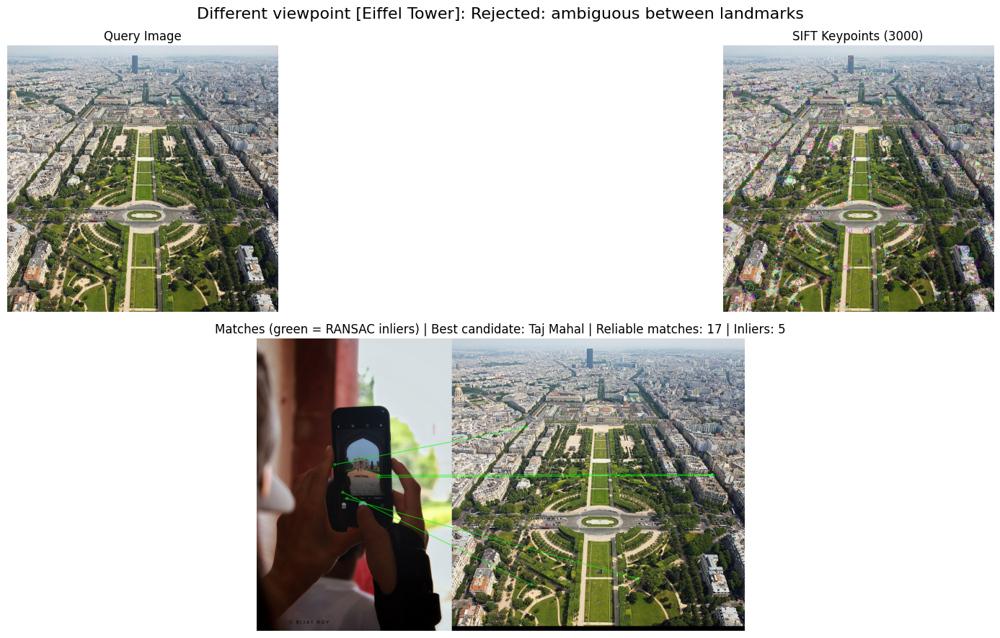

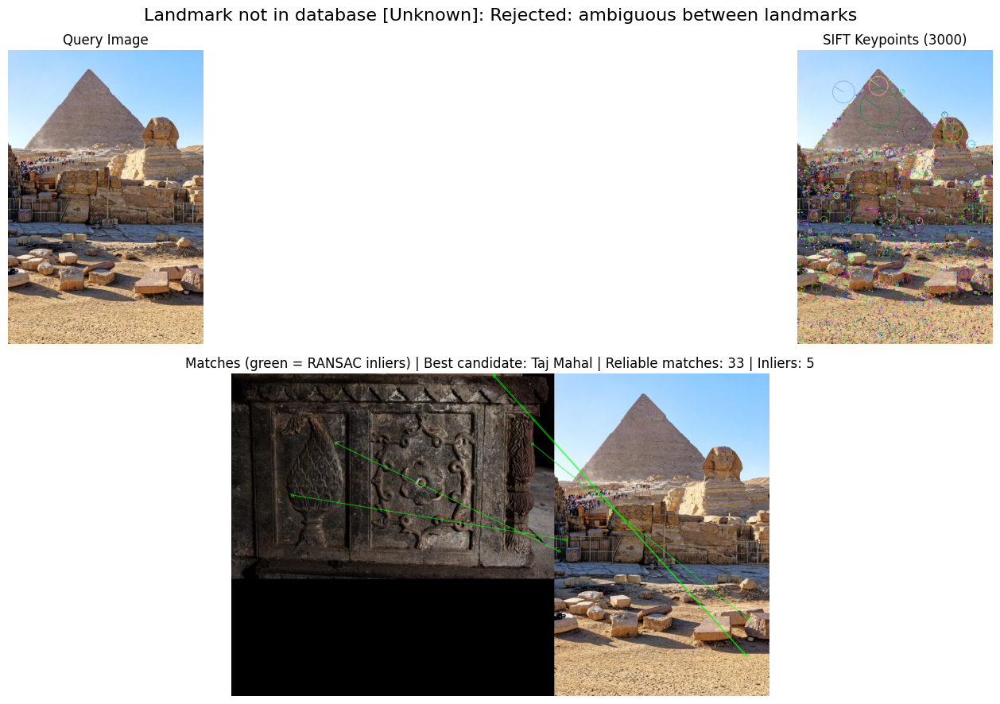

,Test,Ground truth,Predicted landmark,Best candidate,Keypoints,Reliable matches,RANSAC inliers,Decision,Correct,Time (s)
0,Original,Eiffel Tower,Eiffel Tower,Eiffel Tower,827,827,827,Recognized,True,2.621
1,Rotated (45 deg),Eiffel Tower,Eiffel Tower,Eiffel Tower,1152,586,570,Recognized,True,3.711
2,Resized (50%),Eiffel Tower,Eiffel Tower,Eiffel Tower,237,164,162,Recognized,True,0.774
3,Reduced brightness,Eiffel Tower,Eiffel Tower,Eiffel Tower,509,464,463,Recognized,True,1.728
4,Different viewpoint,Eiffel Tower,Rejected,Taj Mahal,3000,17,5,Rejected,False,9.108
5,Original,Taj Mahal,Taj Mahal,Taj Mahal,337,337,337,Recognized,True,1.275
6,Rotated (45 deg),Taj Mahal,Taj Mahal,Taj Mahal,393,210,201,Recognized,True,1.378
7,Resized (50%),Taj Mahal,Taj Mahal,Taj Mahal,195,164,159,Recognized,True,0.613
8,Reduced brightness,Taj Mahal,Taj Mahal,Taj Mahal,199,185,185,Recognized,True,0.693
9,Different viewpoint,Taj Mahal,Taj Mahal,Taj Mahal,1927,156,105,Recognized,True,5.871


In [34]:
FIGURE_LANDMARK = "Eiffel Tower"

records = []
figure_index = 1

all_tests = []
for name in LANDMARKS:
    all_tests.extend(build_tests(name))
all_tests.append(("Landmark not in database", "Unknown", unknown_image))

for test_name, truth, img in all_tests:
    res = recognize(img)
    if res["recognized"]:
        correct = res["top"]["landmark"] == truth
    else:
        correct = truth == "Unknown"
    records.append({
        "Test": test_name,
        "Ground truth": truth,
        "Predicted landmark": res["top"]["landmark"] if res["recognized"] else "Rejected",
        "Best candidate": res["top"]["landmark"],
        "Keypoints": len(res["kp"]),
        "Reliable matches": res["top"]["reliable_matches"],
        "RANSAC inliers": res["inliers"],
        "Decision": "Recognized" if res["recognized"] else "Rejected",
        "Correct": correct,
        "Time (s)": round(res["time"], 3),
    })
    if truth in (FIGURE_LANDMARK, "Unknown"):
        show_result(res, f"{test_name} [{truth}]", f"fig_06_test_{figure_index:02d}.png")
        figure_index += 1

results = pd.DataFrame(records)
results.to_csv("evaluation_results.csv", index=False)
results

In [35]:
recognition_tests = results[results["Ground truth"] != "Unknown"]
unknown_tests = results[results["Ground truth"] == "Unknown"]

print(f"Recognition accuracy on known landmarks : {recognition_tests['Correct'].mean() * 100:.1f}%")
print(f"Unknown landmark correctly rejected     : {bool(unknown_tests['Correct'].all())}")
print(f"Average processing time                 : {results['Time (s)'].mean():.3f} s")

by_condition = recognition_tests.groupby("Test").agg(
    accuracy=("Correct", "mean"),
    avg_matches=("Reliable matches", "mean"),
    avg_inliers=("RANSAC inliers", "mean"),
    avg_time=("Time (s)", "mean"),
).round(2)
by_condition

Recognition accuracy on known landmarks : 84.0%
Unknown landmark correctly rejected     : True
Average processing time                 : 5.194 s


,accuracy,avg_matches,avg_inliers,avg_time
Test,,,,
Different viewpoint,0.2,53.2,25.8,8.04
Original,1.0,1920.0,1920.0,5.86
Reduced brightness,1.0,827.6,825.6,2.83
Resized (50%),1.0,447.2,444.0,1.96
Rotated (45 deg),1.0,1082.2,1064.2,6.50


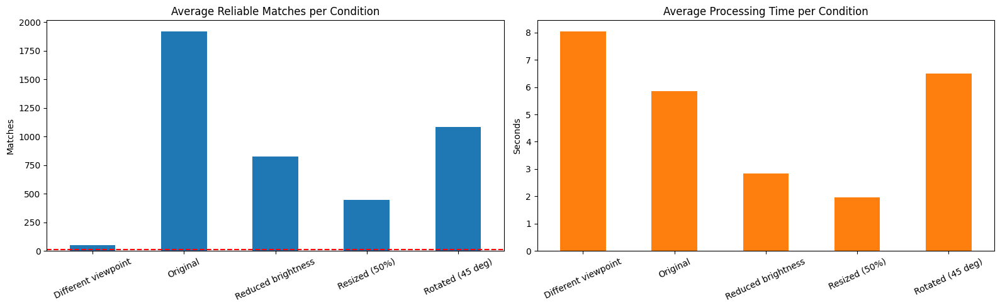

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
by_condition["avg_matches"].plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].axhline(MIN_GOOD, color="red", linestyle="--")
axes[0].set_title("Average Reliable Matches per Condition")
axes[0].set_ylabel("Matches")
by_condition["avg_time"].plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set_title("Average Processing Time per Condition")
axes[1].set_ylabel("Seconds")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig("fig_07_performance_summary.png", dpi=150, bbox_inches="tight")
plt.show()